# 04 · Population activity and dimensionality reduction — **Python / pynapple**

So far we looked at one neuron (notebooks 01 and 02) or one pair of neurons (notebook 03) at a
time. But we record ~200 prefrontal units at once. At each moment, the population activity is a
point in a space with **one axis per neuron**: ~200 dimensions, impossible to look at. Yet the
neurons are not independent: many of them go up and down together. **Dimensionality reduction**
finds a few directions (combinations of neurons) that capture most of this shared activity.

This notebook is a short tour of several methods, with what each of them is good for:

1. **PCA** (principal component analysis) on the trial-averaged activity: the main patterns of
   the population response, and how it changes from block to block;
2. **hierarchical clustering** of the units, described by their first 20 PCs: groups of units
   with similar responses;
3. **coding directions**: directions chosen to separate two conditions (sound, aversive
   stimulus, state of the mouse);
4. **TCA** (tensor component analysis) on the single-trial activity: patterns across neurons,
   **time within a trial**, and **trials** at once;
5. **UMAP** and a **self-organizing map (SOM)**: non-linear maps of the units themselves,
   described by the firing features of notebooks 01 and 02 (rate, burstiness, memory, waveform).

**Dataset.** Session `156131_20191112-probe0`, the same as in notebooks 01–03, with the trials of
blocks 1–4 (see the trial structure in notebook 01, section 1) and the units of the four
prefrontal areas (ACA, PL, ILA, ORB).

## 0. Get the data

The session is on the [DANDI Archive](https://dandiarchive.org), in
[Dandiset 000473](https://dandiarchive.org/dandiset/000473): we use the file
`sub-156131/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb` (5.6 GB), the same as in
notebook 01. If you already downloaded it, just write its path in `NWB` below.

**Option 1 (recommended): download the file** to a folder of your choice on your computer
(keep it out of the git repo: it is far too big for GitHub). Either:

- in the browser: open the
  [files of the Dandiset](https://dandiarchive.org/dandiset/000473/0.261102.1657/files?location=sub-156131),
  and click the download icon next to the file;
- or in a terminal, from the `python/` folder, with the DANDI command-line tool
  (replace `/path/to/your/data/folder` by the folder where you want to save the file):

  ```bash
  uv run dandi download -o /path/to/your/data/folder "https://api.dandiarchive.org/api/assets/6b424b64-764a-4677-a828-49094420e930/download/"
  ```

Then write the full path to the file in `NWB` in the cell below.

**Option 2 (advanced): stream the file from DANDI**, without downloading it: set `STREAM = True`
below (see section 0 of notebook 01).

In [1]:
# numpy: arrays and maths; matplotlib: figures; pandas: tables; pynapple: spike trains;
# h5py: low-level access to the NWB file; scikit-learn: PCA; scipy: hierarchical clustering;
# tensorly: TCA; umap: UMAP; minisom: self-organizing maps
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pynapple as nap
import h5py
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import tensorly as tl
from tensorly.decomposition import non_negative_parafac
import umap
from minisom import MiniSom

# Option 1: full path to the NWB file you downloaded. Change it to where you saved it.
NWB = "/path/to/your/data/folder/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb"

# Option 2: set to True to stream the file from the DANDI Archive instead
STREAM = True

if not STREAM and not Path(NWB).is_file():
    raise FileNotFoundError(f"No NWB file at {NWB}: set NWB to the downloaded file, or STREAM = True")

if STREAM:
    import remfile
    from dandi.dandiapi import DandiAPIClient

    DANDISET, VERSION = "000473", "0.261102.1657"  # Dandiset id and published version
    ASSET = "sub-156131/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb"
    with DandiAPIClient() as client:
        asset = client.get_dandiset(DANDISET, VERSION).get_asset_by_path(ASSET)
        url = asset.get_content_url(follow_redirects=1, strip_query=True)
    print("streaming from", url)


def open_nwb():
    """Open the NWB file with h5py: the local file, or the remote one if STREAM is True."""
    return h5py.File(remfile.File(url) if STREAM else NWB, "r")

/Users/pierre/Documents/Minischool_GDR2026_SpikeTrains/python/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


streaming from https://dandiarchive.s3.amazonaws.com/blobs/32e/6d3/32e6d36c-b7dc-4e91-af59-7073696e6f68


## 1. Load the units and the trials

Same steps as in notebook 01 (sections 1 and 2): the trials of blocks 1–4, and the units of
ACA, PL, ILA and ORB that pass the quality criteria. We also keep the trough-to-peak duration
We do not remove the saturation periods here (notebook 01, section 1.1): they fall outside the
trials and only touch a few windows between them, so their effect is negligible.
of the waveform (`Peak_to_Trough`, read by pynapple) to classify the units into **narrow** and
**wide** waveforms with the two thresholds of notebook 02 (section 3.1).

In [2]:
if STREAM:
    import pynwb
    data = nap.NWBFile(pynwb.NWBHDF5IO(file=open_nwb()).read())  # remote file
else:
    data = nap.load_file(NWB)  # open the file and list its content

units = data["units"]  # all sorted units (TsGroup)
trials = data["trials"]  # task trials (IntervalSet)
trials = trials[trials.Block <= 4]  # blocks 1-4

with open_nwb() as f:
    isi_fp = f["units/quality"][:, 1]  # ISI violation false-positive rate
    fs = f["units/FS"][:] == 1  # fast-spiking label of the file
    rs = f["units/RS"][:] == 1  # regular-spiking label of the file

presence_ratio = (units.count(units.time_support.tot_length() / 100).values > 0).mean(axis=0)
area = units.location.str.extract(r"^(ACA|PL|ILA|ORB)", expand=False)  # NaN outside the 4 areas
units.set_info(isi_fp=isi_fp, plausible=fs | rs, presence_ratio=presence_ratio, area=area)
pfc = units[units.area.notna() & (units.isi_fp < 0.1) & units.plausible & (units.presence_ratio > 0)]

low_th, high_th = 0.380, 0.430  # ms, the thresholds of notebook 02
pfc.set_info(wf_class=np.select([pfc.Peak_to_Trough < low_th, pfc.Peak_to_Trough > high_th],
                                ["narrow", "wide"], default="unclassified"))

block = trials.Block.astype(int)  # block of each trial: 1, 2, 3 or 4
block_names = {1: "sound (pre)", 2: "sound + opto", 3: "sound (post)", 4: "air puff"}
block_colors = {1: "tab:blue", 2: "tab:purple", 3: "tab:cyan", 4: "tab:orange"}
area_colors = {"ACA": "C0", "PL": "C1", "ILA": "C2", "ORB": "C4"}
print("trials:", len(trials), "| PFC units:", len(pfc))
print(pfc.area.value_counts().to_string())

trials: 250 | PFC units: 192
area
ORB    78
PL     76
ILA    21
ACA    17


## 2. The population tensor

Mucho important here!! The population tensor is the entry data format for many population analysis techniques. We will work in the realm of binned activity and loose a lot of temporal infomation (nooooo 😭 !!). For each unit and each trial, we count the spikes in 10 ms bins, from 1 s before to 2 s after
the trial onset. Pynapple does it for us in one call with `nap.build_tensor`: it returns a 3D array, a
**tensor**, of shape (units × trials × time bins). We divide by the bin size to get rates (Hz),
and smooth each trial in time with a Gaussian kernel (σ = 1 bin, 10 ms), to reduce the noise of
single trials. Small bins keep the fast responses (the onset and the air puff are sharp), but each
bin holds few spikes: the PSTHs below are noisy. Try `bin_size = 0.1` (100 ms) to compare.

In [4]:
bin_size = 0.01  # s
window = nap.IntervalSet(start=trials.start - 1, end=trials.start + 2)  # -1 to +2 s around onset
rates = nap.build_tensor(pfc, window, bin_size=bin_size) / bin_size  # (units, trials, bins), in Hz
rates = gaussian_filter1d(rates, sigma=1, axis=2)  # smooth along time
t_bins = np.arange(rates.shape[2]) * bin_size - 1 + bin_size / 2  # center of each bin, in s
print("tensor (units x trials x bins):", rates.shape)

tensor (units x trials x bins): (192, 250, 300)


Averaging over the trials of each block gives one PSTH per unit and per block. We put the 4
blocks side by side, and **z-score** each unit (subtract its mean, divide by its standard
deviation): otherwise the fast units would dominate everything that follows. Below, one row per
unit, sorted by its response to the pre-conditioning sound.

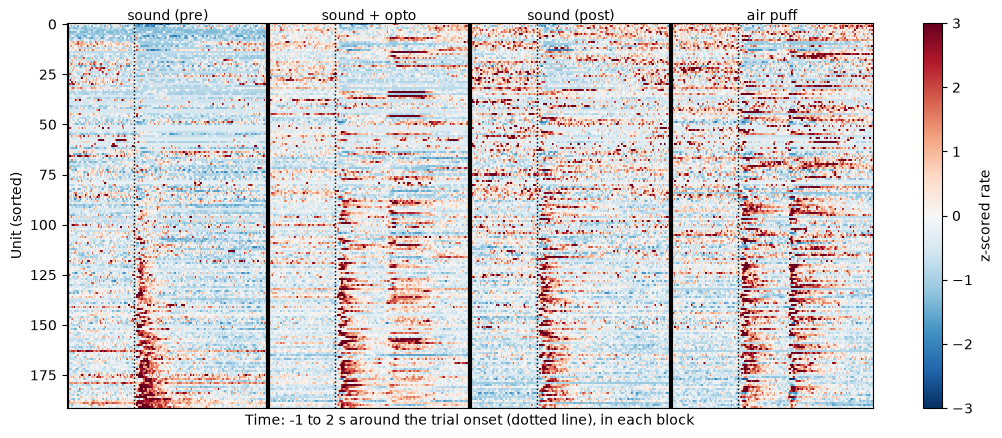

In [5]:
psth = np.concatenate([rates[:, block == b].mean(axis=1) for b in block_names], axis=1)  # units x (4 x bins)
z = (psth - psth.mean(axis=1, keepdims=True)) / psth.std(axis=1, keepdims=True)
n_bins = len(t_bins)
order = np.argsort(z[:, :n_bins][:, (t_bins > 0) & (t_bins < 0.5)].mean(axis=1))  # response 0-0.5 s, block 1

fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(z[order], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="none")
onset = np.searchsorted(t_bins, 0)  # first bin after the trial onset
for k, b in enumerate(block_names):
    ax.axvline(k * n_bins - 0.5, color="k", lw=3)  # start of each block
    ax.axvline(k * n_bins + onset - 0.5, color="k", ls=":", lw=1)  # trial onset in each block
    ax.text(k * n_bins + n_bins / 2, -2, block_names[b], ha="center")
ax.set(xticks=[], xlabel="Time: -1 to 2 s around the trial onset (dotted line), in each block",
       ylabel="Unit (sorted)")
plt.colorbar(im, label="z-scored rate")
plt.show()

Many units are excited just after the trial onset (red after the dotted line), others are
inhibited (blue). The pattern is similar in the four blocks, but not identical: in blocks 2 and 4,
a second wave of activity comes later: the response to the aversive stimulus, which starts 0.7 s
after the onset (optogenetics in block 2, from 0.7 to 1.2 s; air puff in block 4, a sharp
response around 0.8 s).

## 3. PCA: the main patterns of the population

### 3.1 Principal components

PCA looks for the direction in the 192-dimensional space (a weighted sum of the units) along
which the data vary the most: the first **principal component** (PC1). Then the direction, at
right angles to PC1, with the most remaining variance: PC2, and so on. Each PC has:

- **loadings** (or weights): one value per unit, how much the unit contributes;
- a **score** (or projection): one value per time point, the activity of the population
  along this direction.

Here the "samples" are the 4 × 300 time bins and the "features" are the units.

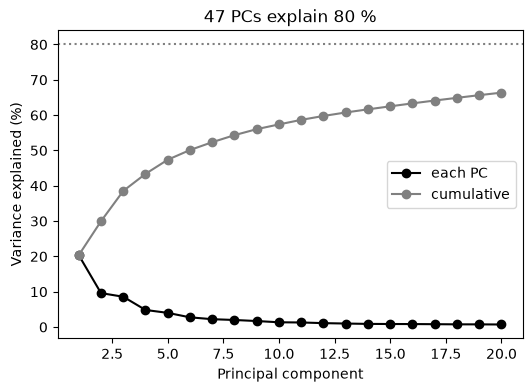

In [6]:
pca = PCA()
scores = pca.fit_transform(z.T)  # (4 x bins) x components: one row per time bin
explained = pca.explained_variance_ratio_  # fraction of the variance of each PC
n80 = np.searchsorted(np.cumsum(explained), 0.8) + 1  # number of PCs for 80 % of the variance

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, 21), 100 * explained[:20], "ko-", label="each PC")
ax.plot(np.arange(1, 21), 100 * np.cumsum(explained[:20]), "o-", color="gray", label="cumulative")
ax.axhline(80, color="gray", ls=":")
ax.set(xlabel="Principal component", ylabel="Variance explained (%)", title=f"{n80} PCs explain 80 %")
ax.legend()
plt.show()

The first few PCs explain a large part of the variance of 192 units: the trial-averaged activity
is **low-dimensional**. With 10 ms bins, though, many PCs are needed to reach 80 %: the remaining
variance is mostly fast noise that the small bins keep. (With `bin_size = 0.1`, about 8 PCs
reach 80 %. And careful: averaging over trials already removed most of the noise, which makes the
data look more low-dimensional than single trials.)

### 3.2 What do the PCs look like?

We plot the scores of the first 3 PCs against time, one curve per block, and the population
**trajectory** in the plane of PC1 and PC2: each point is the state of the population at one
moment, and the trajectory goes from 1 s before to 2 s after the onset.

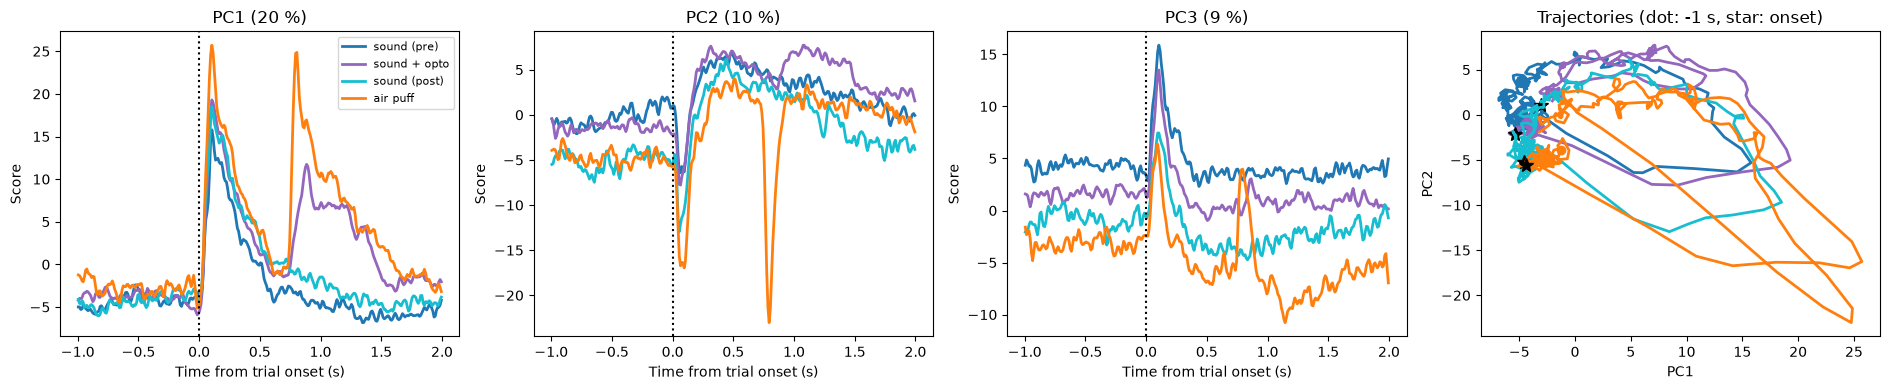

In [7]:
scores_blocks = scores[:, :3].reshape(4, n_bins, 3)  # block x time bin x PC

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for k, b in enumerate(block_names):
    for pc in range(3):
        axes[pc].plot(t_bins, scores_blocks[k, :, pc], color=block_colors[b], lw=2, label=block_names[b])
    axes[3].plot(scores_blocks[k, :, 0], scores_blocks[k, :, 1], color=block_colors[b], lw=2)
    axes[3].plot(*scores_blocks[k, 0, :2], "o", color=block_colors[b])  # start: 1 s before onset
    axes[3].plot(*scores_blocks[k, onset, :2], "k*", ms=10)  # trial onset
for pc in range(3):
    axes[pc].axvline(0, color="k", ls=":")
    axes[pc].set(xlabel="Time from trial onset (s)", ylabel="Score",
                 title=f"PC{pc + 1} ({100 * explained[pc]:.0f} %)")
axes[0].legend(fontsize=8)
axes[3].set(xlabel="PC1", ylabel="PC2", title="Trajectories (dot: -1 s, star: onset)")
plt.tight_layout()
plt.show()

- **PC1** is the response common to all the blocks: the population jumps right after the trial
  onset (a sharp peak in the first 200 ms). In block 4 it jumps a second time, as sharply, about
  0.8 s after the onset: the response to the air puff (at 0.7 s). In block 2 (opto) the second
  response is smaller and lasts longer.
- **PC2** dips just after the onset, then rises and stays up for about a second: a slower part of
  the response. In block 4, it drops sharply at the air puff.
- **PC3** is different in each block **already before the onset**, when nothing has happened
  yet: it decreases steadily from block 1 to block 4. This is not a response, but a slow change of
  the activity over the session (the blocks follow each other in time): a change of the state of
  the mouse, or a **drift** of the recording. We meet it again in section 5.4 and in notebook 05.
  (With `bin_size = 0.1`, this slow change comes out as PC2: the order of the PCs depends on the
  bin size.)
- In the PC1–PC2 plane, each block makes a loop that starts and ends near its own point (the
  activity before the trial). The air puff block makes the largest loop.

### 3.3 Which units make the PCs?

The loadings tell which units contribute to each PC. Do the 4 areas contribute in the same way?

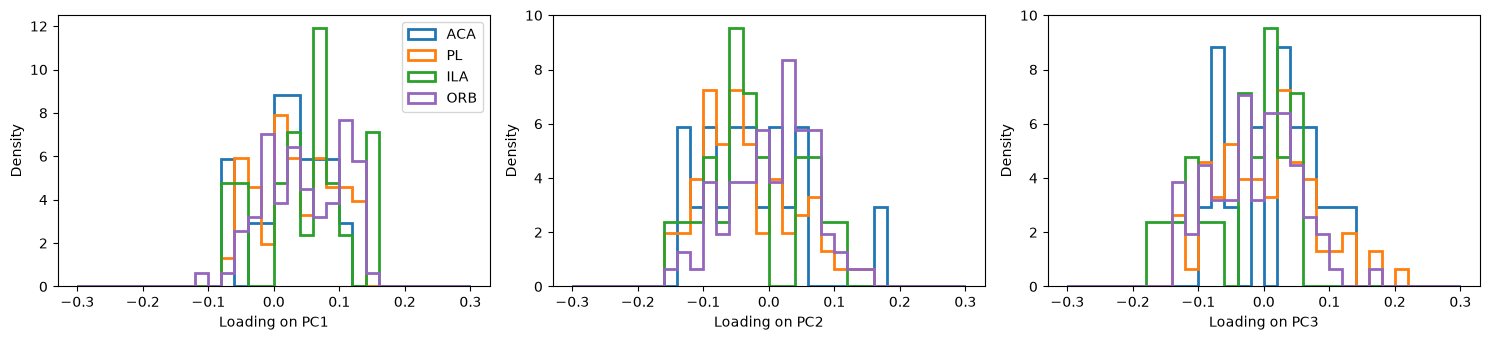

In [8]:
loadings = pd.DataFrame(pca.components_[:3].T, index=pfc.index, columns=["PC1", "PC2", "PC3"])
loadings["area"] = pfc.area.values

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, pc in zip(axes, ["PC1", "PC2", "PC3"]):
    for a, color in area_colors.items():
        ax.hist(loadings[pc][loadings.area == a], bins=np.linspace(-0.3, 0.3, 31), histtype="step",
                lw=2, color=color, density=True, label=a)
    ax.set(xlabel=f"Loading on {pc}", ylabel="Density")
axes[0].legend()
plt.tight_layout()
plt.show()

The loadings of PC1 are mostly positive: most units go up together after the onset. (The
sign of a PC is arbitrary: flipping both its loadings and its scores gives the same PC.) The
loadings of the other PCs are spread around 0 in all the areas: every PC mixes units of the four
areas, with positive and negative weights. A PC is a pattern of the **population**, not of an
area.

### 3.4 The trajectories in 3D

PC1 and PC2 do not tell the whole story: PC3 carries the slow change between blocks. With the
first **three** PCs, we can draw the trajectories in 3D. Each block is a loop that leaves its
starting point at the trial onset (star), and comes back. We draw the same plot from two points
of view: a 3D plot is a 2D picture, and one view can hide what another shows.
(In Jupyter, `%matplotlib widget` makes the plot interactive: you can rotate it with the mouse.
It needs the `ipympl` package.)

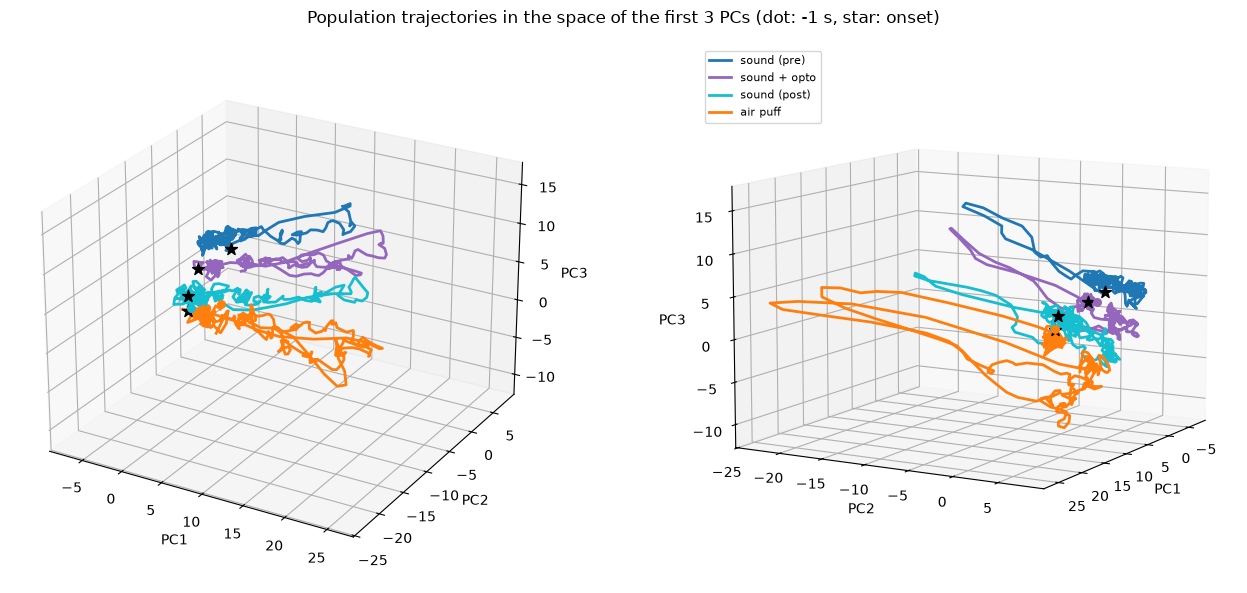

In [9]:
scores_3d = scores[:, :3].reshape(4, n_bins, 3)  # block x time bin x (PC1, PC2, PC3)

fig = plt.figure(figsize=(14, 6))
for v, (elev, azim) in enumerate([(25, -60), (10, 30)]):  # two points of view (angles in degrees)
    ax = fig.add_subplot(1, 2, v + 1, projection="3d")  # a 3D axis
    for k, b in enumerate(block_names):
        x, y, zz = scores_3d[k].T  # PC1, PC2 and PC3 of block b, over time
        ax.plot(x, y, zz, color=block_colors[b], lw=2, label=block_names[b])
        ax.scatter(x[0], y[0], zz[0], color=block_colors[b], s=30)  # start: 1 s before the onset
        ax.scatter(x[onset], y[onset], zz[onset], color="k", marker="*", s=80)  # trial onset
    ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3")
    ax.view_init(elev=elev, azim=azim)  # elevation and azimuth of the point of view
ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Population trajectories in the space of the first 3 PCs (dot: -1 s, star: onset)")
plt.tight_layout()
plt.show()

The loops of the 4 blocks are **shifted** from each other along PC3 (the slow change over the
session, from block 1 at the top to block 4 at the bottom), but they leave in the same direction
after the onset: the response to the stimulus has a similar shape in all the blocks. Block 4
makes a second, large excursion along PC1 and PC2 at the air puff.

**Questions.**

- Run the PCA without z-scoring (`psth - psth.mean(...)` only). Which units dominate PC1 now?
- Run the PCA on the units of one area only. Are the first PCs the same?
- Fit the PCA on blocks 1 and 4 only, and project block 3 on these PCs (`pca.transform`).

## 4. Hierarchical clustering of the units

PCA described the **time** course of the population. We now turn the question around: are there
**groups of units** with similar responses? To answer it, we describe each unit by its response,
and group the units whose responses are close.

### 4.1 The features: the first 20 PCs of the responses

The response of a unit is its z-scored PSTH in the 4 blocks: 1200 numbers (4 blocks × 300 bins),
many of them redundant and noisy. As in section 3, PCA compresses them, but now the **units are
the samples** and the time bins the features: each unit gets 20 numbers, its coordinates on the
first 20 PCs. These 20 numbers keep the main shape of its response and drop much of the noise of
the small bins: they keep about two thirds of the variance.

In [10]:
n_pcs = 20  # number of PCs used to describe each unit
pca_units = PCA(n_pcs)
unit_features = pca_units.fit_transform(z)  # units x 20: the coordinates of each unit
print(f"the first {n_pcs} PCs keep {100 * pca_units.explained_variance_ratio_.sum():.0f} % "
      "of the variance of the responses")

the first 20 PCs keep 64 % of the variance of the responses


### 4.2 Ward's method and the dendrogram

**Hierarchical clustering** starts with each unit in its own cluster, and merges the two closest
clusters, again and again, until all the units are in one cluster. **Ward's method** chooses, at
each step, the merge that increases the least the spread of the units around the centers of
their clusters (the within-cluster variance). It tends to make compact clusters of similar sizes.

The result is a tree, the **dendrogram**: two branches join at the height of their merge. A
large height means that two very different groups were merged. We cut the tree where the
branches are long: here, at **4 clusters** (the dashed line).

height of the last merges: [ 85.6 104.5 109.5 125.  134.4 205.1]


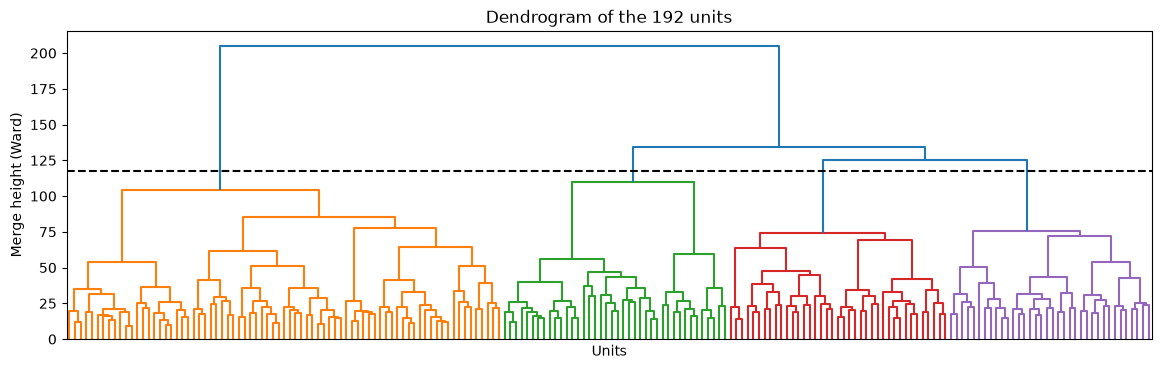

In [11]:
tree = linkage(unit_features, method="ward")  # the sequence of merges (scipy)
n_clusters_h = 4  # number of clusters: where we cut the tree
cut_height = (tree[-n_clusters_h, 2] + tree[-n_clusters_h + 1, 2]) / 2  # between 2 merges
print("height of the last merges:", np.round(tree[-6:, 2], 1))

fig, ax = plt.subplots(figsize=(14, 4))
dendro = dendrogram(tree, color_threshold=cut_height, no_labels=True, ax=ax)  # draw the tree
ax.axhline(cut_height, color="k", ls="--")
ax.set(ylabel="Merge height (Ward)", xlabel="Units", title="Dendrogram of the 192 units")
plt.show()

`fcluster` cuts the tree into the clusters. The dendrogram also gives an **order** of the units
(`leaves`): units of the same branch are next to each other. We use it to sort the heatmap of
section 2: the clusters appear as bands of units with similar responses.

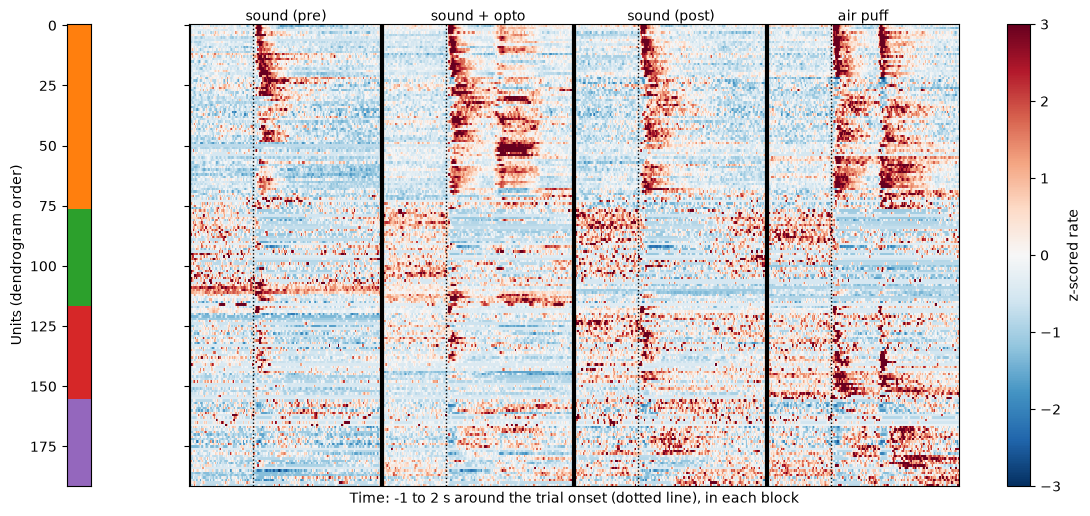

In [12]:
cluster_h = fcluster(tree, n_clusters_h, criterion="maxclust")  # cluster of each unit: 1 to 4
leaves = dendro["leaves"]  # order of the units along the dendrogram

# Color of each cluster: the color of its branch in the dendrogram
cluster_colors = {cluster_h[u]: color for u, color in zip(leaves, dendro["leaves_color_list"])}

fig, (ax_c, ax) = plt.subplots(1, 2, figsize=(14, 6), width_ratios=[1, 40], sharey=True)
for row, u in enumerate(leaves):  # color bar: one colored line per unit, the color of its cluster
    ax_c.axhspan(row - 0.5, row + 0.5, color=cluster_colors[cluster_h[u]], lw=0)
ax_c.set(xticks=[], ylim=(len(leaves) - 0.5, -0.5), ylabel="Units (dendrogram order)")
im = ax.imshow(z[leaves], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="none")
for k, b in enumerate(block_names):
    ax.axvline(k * n_bins - 0.5, color="k", lw=3)  # start of each block
    ax.axvline(k * n_bins + onset - 0.5, color="k", ls=":", lw=1)  # trial onset in each block
    ax.text(k * n_bins + n_bins / 2, -2, block_names[b], ha="center")
ax.set(xticks=[], xlabel="Time: -1 to 2 s around the trial onset (dotted line), in each block")
plt.colorbar(im, ax=ax, label="z-scored rate")
plt.show()

### 4.3 The response of each cluster

The mean z-scored PSTH of the units of each cluster, in each block:

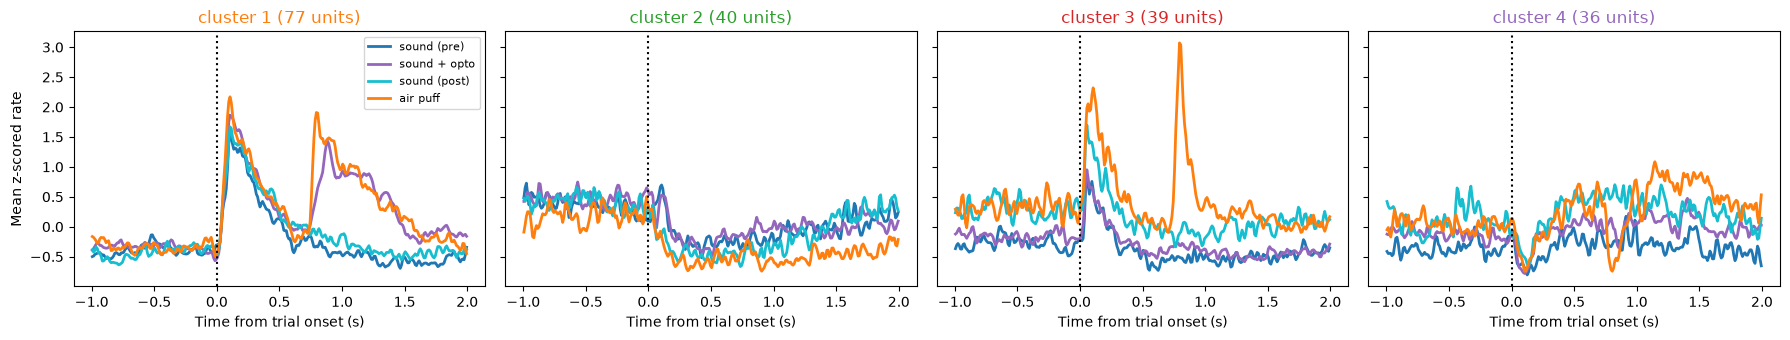

area,ACA,ILA,ORB,PL
cluster,,,,
1,4,8,38,27
2,5,5,10,20
3,6,4,9,20
4,2,4,21,9


In [13]:
fig, axes = plt.subplots(1, n_clusters_h, figsize=(18, 3.5), sharey=True)
for ax, c in zip(axes, range(1, n_clusters_h + 1)):
    members = cluster_h == c  # units of cluster c
    for k, b in enumerate(block_names):
        ax.plot(t_bins, z[members, k * n_bins:(k + 1) * n_bins].mean(axis=0), color=block_colors[b],
                lw=2, label=block_names[b])
    ax.axvline(0, color="k", ls=":")
    ax.set(xlabel="Time from trial onset (s)")
    ax.set_title(f"cluster {c} ({members.sum()} units)", color=cluster_colors[c])
axes[0].set_ylabel("Mean z-scored rate")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# How many units of each area in each cluster?
pd.crosstab(pd.Series(cluster_h, name="cluster"), pd.Series(pfc.area.values, name="area"))

The four clusters have clearly different responses:

1. **inhibited** after the onset, in all the blocks;
2. a **slow increase** after the onset, which lasts the whole trial in blocks 2, 3 and 4, and is
   almost absent in block 1;
3. **excited at the onset** in all the blocks, with a second, long response in block 2: these
   units respond to the **optogenetic** stimulation (0.7 to 1.2 s);
4. **excited at the onset** in all the blocks, with a sharp second response in block 4: these
   units respond to the **air puff** (at 0.7 s). It is the largest cluster.

All four clusters contain units of the four areas: as for the PCs, the response types are not
tied to one area.

**Careful.** Hierarchical clustering, like k-means, always returns clusters, even when the
responses form a continuum. The number of clusters is our choice, and the clusters depend on the
features (z-scoring, number of PCs, time window). Check that a cluster has a meaning beyond the
data that made it: does it come back with another number of PCs? Is it enriched in one area, or in
narrow-waveform units (notebook 02)?

**Questions.**

- Cut the tree at 3 or 6 clusters. Which clusters split or merge?
- Use 5 or 50 PCs instead of 20 (`n_pcs`). Are the clusters the same
  (`pd.crosstab(cluster_h, new_clusters)`)?
- Try `method="average"` instead of `"ward"` in `linkage`. What changes in the dendrogram?

## 5. Coding directions

PCA finds the directions of largest variance, whatever their cause. Often we have a more precise
question: along which direction does the population **separate two conditions**? The Svoboda lab
([Li et al., 2016](https://doi.org/10.1038/nature17643)) answers it with the **coding direction**
(CD): the difference between the mean population activity in condition A and in condition B,

$$ \mathrm{CD} = \frac{\bar{r}_A - \bar{r}_B}{\lVert \bar{r}_A - \bar{r}_B \rVert} $$

where $\bar{r}_A$ is a vector with the mean rate of each unit in condition A. Dividing by the
length (the norm) makes CD a direction of length 1. **Projecting** the activity on CD (a dot
product: $\sum_n \mathrm{CD}_n\, r_n$) gives one number per trial and time bin: how much the
population looks like A rather than B.

Two precautions, as in Li et al.:

- we **z-score** each unit over all the trials and bins, so that the fast units do not dominate;
- we compute the CD on **half of the trials** (training trials), and project the **other half**
  (test trials). On the trials used to build it, a CD always separates the conditions, even for
  pure noise: only the test trials tell whether the separation is real.

We compute three coding directions:

1. **sound**: after vs before the trial onset (the sound starts at the onset);
2. **opto vs air puff**: the response in block 2 vs block 4, while the aversive stimulus is on
   (0.7–1.2 s after the onset);
3. **state**: the activity *before* the onset in block 1 vs block 4: no stimulus, only the slow
   change of the activity over the session (PC3 in section 3).

### 5.1 Training and test trials

In [18]:
rates_z = (rates - rates.mean(axis=(1, 2), keepdims=True)) / rates.std(axis=(1, 2), keepdims=True)
block_arr = np.asarray(block)  # block of each trial, as a numpy array

rng = np.random.default_rng(seed=42)  # random generator with a fixed seed: same split for everyone
train = np.zeros(len(trials), bool)
for b in block_names:  # half of the trials of each block for training, the rest for testing
    in_block = np.flatnonzero(block_arr == b)
    train[rng.choice(in_block, size=len(in_block) // 2, replace=False)] = True
test = ~train
print("training trials:", train.sum(), "| test trials:", test.sum())


def in_window(start, end):
    """Boolean mask of the time bins between start and end (s, relative to the trial onset)."""
    return (t_bins > start) & (t_bins < end)


def unit_vector(v):
    """Divide a vector by its length: a direction of length 1."""
    return v / np.linalg.norm(v)


def d_prime(a, b):
    """Separation of two sets of values: difference of the means / pooled standard deviation."""
    return (np.mean(a) - np.mean(b)) / np.sqrt((np.var(a) + np.var(b)) / 2)


# Projection of every trial and time bin on a direction: a sum over the units (axis 0)
def project(direction, activity):
    """activity: units x trials x bins. Returns trials x bins."""
    return np.einsum("u,utb->tb", direction, activity)

training trials: 125 | test trials: 125


### 5.2 The sound coding direction

Condition A: the first 0.5 s after the onset; condition B: the 0.5 s before. We average over the
training trials of all the blocks, and project the test trials.

d' on the test trials (after vs before the onset): 3.01


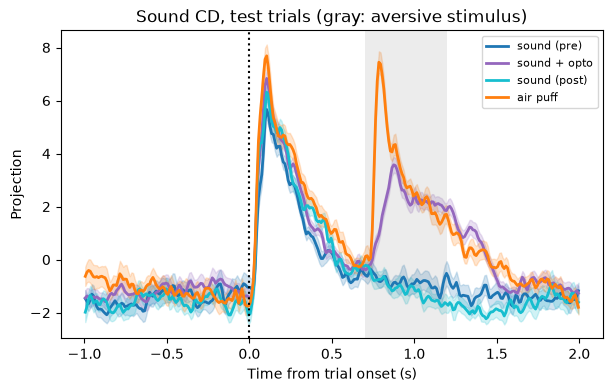

In [19]:
post, pre = in_window(0, 0.5), in_window(-0.5, 0)
cd_sound = unit_vector(rates_z[:, train][:, :, post].mean(axis=(1, 2))
                       - rates_z[:, train][:, :, pre].mean(axis=(1, 2)))
proj_sound = project(cd_sound, rates_z)  # trials x bins

print("d' on the test trials (after vs before the onset):",
      round(d_prime(proj_sound[test][:, post].mean(axis=1), proj_sound[test][:, pre].mean(axis=1)), 2))


def plot_projection(ax, proj, trials_mask, title):
    """Mean +- standard error of a projection over the selected trials, one curve per block."""
    for b in block_names:
        sel = trials_mask & (block_arr == b)
        mean = proj[sel].mean(axis=0)
        sem = proj[sel].std(axis=0) / np.sqrt(sel.sum())  # standard error of the mean
        ax.plot(t_bins, mean, color=block_colors[b], lw=2, label=block_names[b])
        ax.fill_between(t_bins, mean - sem, mean + sem, color=block_colors[b], alpha=0.2)
    ax.axvline(0, color="k", ls=":")
    ax.axvspan(0.7, 1.2, color="gray", alpha=0.15, lw=0)  # aversive stimulus (blocks 2 and 4)
    ax.set(xlabel="Time from trial onset (s)", ylabel="Projection", title=title)


fig, ax = plt.subplots(figsize=(7, 4))
plot_projection(ax, proj_sound, test, "Sound CD, test trials (gray: aversive stimulus)")
ax.legend(fontsize=8)
plt.show()

On the test trials, the projection jumps right after the onset in all the blocks: the CD
generalizes to trials it has never seen. In blocks 2 and 4 the projection rises again during the
aversive stimulus: part of the population responds to both.

### 5.3 The opto vs air puff coding direction

Both aversive stimuli start 0.7 s after the onset: the optogenetic stimulation in block 2
(40 Hz, from 0.7 to 1.2 s) and the air puff in block 4. Condition A: block 2, condition B:
block 4, from 0.7 to 1.2 s.

**The drift problem.** Blocks 2 and 4 are recorded at different times of the session: the CD
would also pick up the slow change of the activity between them (section 3.2). To remove it, we
subtract from each trial its own **baseline**, the mean activity in the second before the onset.
What is left is the *response* to the trial.

d' block 2 vs block 4, test trials, 0.7-1.2 s (stimulus): 4.61
d' block 2 vs block 4, test trials, 0-0.6 s (before it): 1.28


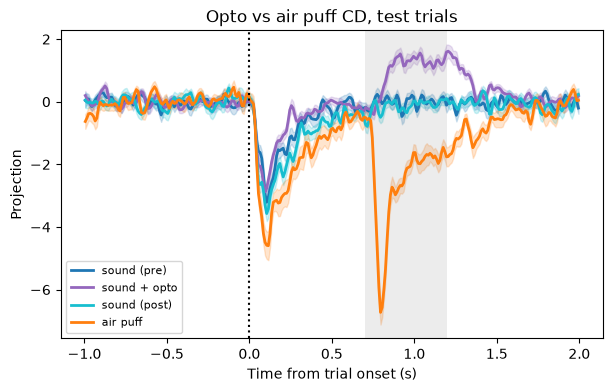

In [20]:
baseline = rates_z[:, :, in_window(-1, 0)].mean(axis=2)  # units x trials: activity before onset
response_z = rates_z - baseline[:, :, None]  # each trial minus its own baseline

aversive = in_window(0.7, 1.2)
cd_aversive = unit_vector(response_z[:, train & (block_arr == 2)][:, :, aversive].mean(axis=(1, 2))
                          - response_z[:, train & (block_arr == 4)][:, :, aversive].mean(axis=(1, 2)))
proj_aversive = project(cd_aversive, response_z)

for name, win in {"0.7-1.2 s (stimulus)": aversive, "0-0.6 s (before it)": in_window(0, 0.6)}.items():
    a = proj_aversive[test & (block_arr == 2)][:, win].mean(axis=1)
    b = proj_aversive[test & (block_arr == 4)][:, win].mean(axis=1)
    print(f"d' block 2 vs block 4, test trials, {name}: {d_prime(a, b):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
plot_projection(ax, proj_aversive, test, "Opto vs air puff CD, test trials")
ax.legend(fontsize=8)
plt.show()

In all the blocks, the projection first dips just after the onset: the response to the sound
partly lies along this direction too (we come back to it in 5.5). The dip is deeper in block 4,
which starts with a different sound (a blue noise instead of a tone): this is why blocks 2 and 4
are already somewhat separated before 0.7 s (d' ≈ 1.3). Then, from 0.7 s, block 4 drops sharply
while block 2 goes up: the two aversive stimuli activate **different combinations of units**,
and the separation is much larger (d' ≈ 4.6). Blocks 1 and 3 (no aversive stimulus) come back
to 0.

### 5.4 The state coding direction

Condition A: the baseline (1 s before the onset) in block 4; condition B: the baseline in
block 1. No stimulus in these windows: this direction captures the **state** of the population
when the mouse waits for the next trial, and how it changes over the session.

d' block 4 vs block 1, test trials: 5.02


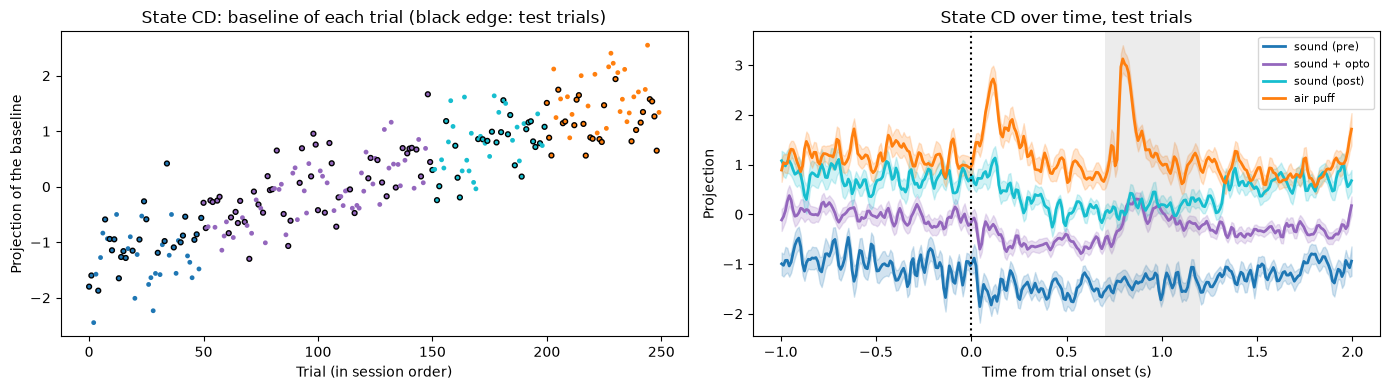

In [21]:
cd_state = unit_vector(baseline[:, train & (block_arr == 4)].mean(axis=1)
                       - baseline[:, train & (block_arr == 1)].mean(axis=1))
proj_state = baseline.T @ cd_state  # one value per trial: its baseline projected on the CD

print("d' block 4 vs block 1, test trials:",
      round(d_prime(proj_state[test & (block_arr == 4)], proj_state[test & (block_arr == 1)]), 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.scatter(np.arange(len(trials)), proj_state, s=12,
            c=[block_colors[b] for b in block_arr], edgecolors=np.where(test, "k", "none"))
ax1.set(xlabel="Trial (in session order)", ylabel="Projection of the baseline",
        title="State CD: baseline of each trial (black edge: test trials)")
plot_projection(ax2, project(cd_state, rates_z), test, "State CD over time, test trials")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

The state CD was built from blocks 1 and 4 only, yet blocks 2 and 3 fall **in between, in the
order of the session**: the baseline activity changes steadily from trial to trial, not only
between blocks 1 and 4. Over time (right), the projection moves a little with the stimuli, but
the offsets between the blocks are larger and last through the whole trial: this direction
mostly carries the state, not the response to the stimuli.

### 5.5 Are the three directions different?

Two directions of length 1 are compared with their **cosine similarity**, the dot product
$\mathrm{CD}_1 \cdot \mathrm{CD}_2$: 1 if they are the same direction, 0 if they are at right
angles (orthogonal), −1 if they are opposite.

In [22]:
cds = {"sound": cd_sound, "opto vs air puff": cd_aversive, "state": cd_state}
cosines = pd.DataFrame([[cds[a] @ cds[b] for b in cds] for a in cds], index=list(cds), columns=list(cds))
cosines.round(2)

,sound,opto vs air puff,state
sound,1.00,-0.29,-0.08
opto vs air puff,-0.29,1.00,0.06
state,-0.08,0.06,1.00


The state direction is almost orthogonal to the two task directions: the slow change of the
baseline and the responses to the stimuli use **different combinations of units**. The sound and
opto-vs-air-puff directions are partly aligned (negatively: the units that respond most to the
sound respond more to the air puff than to the opto).

### 5.6 The trajectories in the space of the three coding directions

As for the PCs in section 3.4, we can use the three coding directions as the three axes of a 3D
plot: each point is the mean activity of the test trials of one block at one moment, projected on
the sound, opto-vs-air-puff and state directions. Here we project the z-scored rates
(`rates_z`, without subtracting the baseline), so that the state axis keeps the differences
between the blocks.

**Careful: the axes are not orthogonal.** Unlike the PCs, the coding directions are not at right
angles (the sound and opto-vs-air-puff directions have a cosine of about −0.3). The plot draws
them at right angles anyway: it is a convenient picture, but distances and angles in it are
distorted, and part of the movement along one axis also shows up along another.

In [ ]:
# Mean activity of the test trials of each block (units x bins), projected on each CD
cd_traj = np.stack([np.stack([cd @ rates_z[:, test & (block_arr == b)].mean(axis=1) for cd in cds.values()],
                             axis=1) for b in block_names])  # block x bins x 3 CDs
labels = list(cds)  # names of the 3 axes

fig = plt.figure(figsize=(14, 6))
for v, (elev, azim) in enumerate([(25, -60), (15, 30)]):  # two points of view (angles in degrees)
    ax = fig.add_subplot(1, 2, v + 1, projection="3d")
    for k, b in enumerate(block_names):
        x, y, zz = cd_traj[k].T  # projections on the sound, opto-vs-air-puff and state CDs
        ax.plot(x, y, zz, color=block_colors[b], lw=2, label=block_names[b])
        ax.scatter(x[0], y[0], zz[0], color=block_colors[b], s=30)  # start: 1 s before the onset
        ax.scatter(x[onset], y[onset], zz[onset], color="k", marker="*", s=80)  # trial onset
    ax.set(xlabel=f"{labels[0]} CD", ylabel=f"{labels[1]} CD", zlabel=f"{labels[2]} CD")
    ax.view_init(elev=elev, azim=azim)
ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Test trials in the space of the 3 coding directions (dot: -1 s, star: onset)")
plt.tight_layout()
plt.show()

Each axis tells one part of the story: the blocks start at different heights on the **state**
axis (the slow change over the session) and all move along the **sound** axis after the onset.
When the aversive stimulus arrives, block 4 (air puff) leaves far along the
**opto-vs-air-puff** axis, on the negative side, while block 2 (opto) moves a little to the
positive side. The opto response looks smaller than in section 5.3: here we did not subtract
the baseline, and the response to the opto is weaker than to the air puff.

**Questions.**

- Compute the sound CD on block 1 only, and project the test trials of block 3 (after the
  conditioning). Is the response to the sound the same?
- Without subtracting the baseline (`rates_z` instead of `response_z`), how well does the opto vs
  air puff CD separate blocks 2 and 4 **before** 0.7 s? Why?
- Change the seed of the training/test split. How much do the d' values change?

## 6. TCA: neurons, time and trials at once

PCA needed the average over trials: it cannot see that the response changes **from trial to
trial** (with learning, habituation, drift...). Tensor component analysis
([Williams et al., 2018](https://doi.org/10.1016/j.neuron.2018.05.015)) works on the whole
tensor (units × time × trials). It writes the tensor as a sum of $R$ components, each the
product of three vectors:

$$ x_{n,t,k} \approx \sum_{r=1}^{R} a_r(n)\, b_r(t)\, c_r(k) $$

- $a_r$: the **neuron factor**, which units take part in component $r$;
- $b_r$: the **time factor**, its time course within a trial;
- $c_r$: the **trial factor**, its strength in each trial.

We use the **non-negative** version (all the factors ≥ 0, like the rates): the components then
add up, and are easier to read. As Williams et al., we divide each unit by its maximum, so that
all the units count. `tensorly` fits the model, starting from random factors: we fit it a few
times (`n_fits`) with different random starts (`seed`), and keep the best fit.

**Be patient:** with 10 ms bins the tensor is large (192 units × 300 bins × 250 trials), and the
next cell fits 30 models: it takes several minutes. With `bin_size = 0.1` (section 2), it takes
seconds.

In [ ]:
tensor = np.transpose(rates, (0, 2, 1))  # units x time x trials
tensor = tensor / tensor.max(axis=(1, 2), keepdims=True)  # each unit divided by its maximum


def fit_tca(tensor, rank, seed=0):
    """Non-negative TCA (CP decomposition). Returns the 3 factors and the relative error."""
    cp = non_negative_parafac(tl.tensor(tensor), rank=rank, n_iter_max=1000, tol=1e-8, init="random",
                              random_state=seed)
    error = np.linalg.norm(tensor - tl.cp_to_tensor(cp)) / np.linalg.norm(tensor)
    return cp.factors, error


def best_tca(tensor, rank, n_fits=5):
    """Fit TCA n_fits times from different random starts, and keep the fit with the lowest error."""
    return min((fit_tca(tensor, rank, seed) for seed in range(n_fits)), key=lambda fit: fit[1])


errors = {rank: best_tca(tensor, rank)[1] for rank in range(1, 7)}

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(errors), list(errors.values()), "ko-")
ax.set(xlabel="Number of components R", ylabel="Relative error", title="TCA: error vs number of components")
plt.show()

The error decreases slowly, and stays very high (~0.86): single-trial spike counts in 10 ms bins
are **noisy** (most bins hold 0 or 1 spike), and most of the variance is noise that no model can
explain. (With 100 ms bins, the error is lower, ~0.6.) There is no clear "elbow": we take
$R = 4$ components, enough to see the main patterns.

In [ ]:
rank = 4
(neuron_f, time_f, trial_f), error = best_tca(tensor, rank)
order_c = np.argsort(np.argmax(time_f, axis=0))  # components sorted by the time of their peak
neuron_f, time_f, trial_f = neuron_f[:, order_c], time_f[:, order_c], trial_f[:, order_c]

fig, axes = plt.subplots(rank, 3, figsize=(15, 2.5 * rank))
unit_order = np.argsort(pfc.area.values)  # units grouped by area
for r in range(rank):
    axes[r, 0].bar(np.arange(len(pfc)), neuron_f[unit_order, r], width=1,
                   color=[area_colors[a] for a in pfc.area.values[unit_order]])
    axes[r, 1].plot(t_bins, time_f[:, r], "k", lw=2)
    axes[r, 1].axvline(0, color="gray", ls=":")
    axes[r, 2].scatter(np.arange(len(trials)), trial_f[:, r], s=8, c=[block_colors[b] for b in block])
    axes[r, 0].set_ylabel(f"component {r + 1}")
axes[0, 0].set_title("Neuron factor (color: area)")
axes[0, 1].set_title("Time factor")
axes[0, 2].set_title("Trial factor (color: block)")
axes[-1, 0].set_xlabel("Units, grouped by area: " + ", ".join(sorted(area_colors)))
axes[-1, 1].set_xlabel("Time from trial onset (s)")
axes[-1, 2].set_xlabel("Trial (in session order)")
plt.tight_layout()
plt.show()

Each component tells a small story: *these* units, with *this* time course, in *these* trials.
The components are sorted by the time of the peak of their time factor:

1. active **before** the onset, and lower after it, with a sharp drop at the onset: the units
   **inhibited** by the stimuli. Its trial factor slowly increases over the session;
2. a sharp **onset response**, peaking ~0.1 s after the onset in all the blocks, with a small
   second peak at the air puff (~0.8 s). Its trial factor is largest at the start of block 4;
3. a slower response that rises after the onset and drops sharply ~0.8 s after it. Its trial
   factor **decreases over the session** and is almost 0 in block 4, which starts with a
   different sound (a blue noise instead of a tone): a response to the **tone** that fades over
   the blocks (**habituation**?);
4. a **late response**, from ~0.7 to 1.5 s after the onset, **absent in blocks 1 and 3** and
   strong in blocks 2 (sound + opto) and 4 (air puff): the response to the **aversive stimulus**
   that follows the sound.

TCA found by itself, without knowing the blocks, that some trials have a late response and
others do not, and that the tone response fades over the session. PCA on trial averages could
not tell us whether a response is there in every trial of a block, or changes within a block.

**Careful.** TCA has no unique solution: the components can come out in a different order, and
a different random start (`seed`) can give different factors. Always fit the model several
times and keep the components that come back every time.

**Questions.**

- Fit TCA with `fit_tca(tensor, 4, seed)` for `seed = 1, 2, 3`. Which components are stable?
- Try $R = 3$ and $R = 5$. Which components split or merge?
- Which units have the largest neuron factor in the response component? Look at their PSTH
  (notebook 01, section 3.5).

## 7. A map of the units: UMAP and self-organizing maps

PCA and TCA reduce the activity over **time**. We can also reduce the **description of the
units**: in notebooks 01 and 02, we described each unit by a few numbers. Do the units form
groups (cell types?) in this feature space? We use four features:

- $\log_{10}$ of the firing rate (notebook 01, section 3.1: the rates span orders of magnitude);
- the **burstiness** $B$ and the **memory** $M$ in the inter-trial intervals (notebook 01,
  sections 4.3 and 5), without the corrections of the advanced sections;
- the **waveform class**: 1 for narrow, 0 for wide (notebook 02, section 3.1).

### 7.1 The features

We compute $B$ and $M$ in the 3 s windows before each trial, as in notebook 01: windows with at
least 4 ISIs, units with at least 12 such windows. We keep the units with a narrow or wide
waveform.

In [ ]:
iti = nap.IntervalSet(start=trials.start - 3, end=trials.start)  # 3 s before each trial
min_isi, min_windows = 4, 12


def isis_per_window(spikes, windows, min_isi=4):
    """List of the ISI arrays of the windows that have at least min_isi ISIs."""
    isis = [np.diff(spikes.restrict(windows[k]).t) for k in range(len(windows))]
    return [isi for isi in isis if len(isi) >= min_isi]


def burstiness(isi):
    """Burstiness B = (std - mean) / (std + mean) of an array of ISIs."""
    return (np.std(isi) - np.mean(isi)) / (np.std(isi) + np.mean(isi))


def memory(isi_list):
    """Memory coefficient: correlation between consecutive ISIs, pooled over windows."""
    current = np.concatenate([isi[:-1] for isi in isi_list])
    following = np.concatenate([isi[1:] for isi in isi_list])
    return np.corrcoef(current, following)[0, 1]


B, M = [], []
for i in pfc.keys():
    isi_list = isis_per_window(pfc[i], iti, min_isi)
    enough = len(isi_list) >= min_windows
    B.append(np.mean([burstiness(isi) for isi in isi_list]) if enough else np.nan)
    M.append(memory(isi_list) if enough else np.nan)
pfc.set_info(burstiness=B, memory=M, log_rate=np.log10(pfc.rate))

units_f = pfc[pfc.burstiness.notna() & (pfc.wf_class != "unclassified")]  # units with all features
features = pd.DataFrame({"log10 rate": units_f.log_rate, "burstiness": units_f.burstiness,
                         "memory": units_f.memory, "narrow": (units_f.wf_class == "narrow").astype(float)})
features_z = (features - features.mean()) / features.std()  # z-score: same weight for every feature
print("units with all the features:", len(features))
features.describe().round(2)

As in PCA, we **z-score** each feature: the distances between units should not depend on the
units of measurement (Hz, no unit...).

### 7.2 UMAP

[UMAP](https://umap-learn.readthedocs.io) (Uniform Manifold Approximation and Projection) places
the units on a 2D map so that units that are **neighbors** in the feature space stay neighbors
on the map. Unlike PCA, it is non-linear: it can unfold curved groups. Its main parameter,
`n_neighbors`, sets how local the map is.

In [ ]:
embedding = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(features_z.values)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes[:3], ["log10 rate", "burstiness", "memory"]):
    sc = ax.scatter(*embedding.T, c=features[col], s=15, cmap="viridis")
    plt.colorbar(sc, ax=ax)
    ax.set(title=f"color: {col}")
for c, color in {"wide": "tab:blue", "narrow": "tab:red"}.items():
    sel = units_f.wf_class.values == c
    axes[3].scatter(*embedding[sel].T, s=15, color=color, label=c)
axes[3].set(title="color: waveform class")
axes[3].legend()
for ax in axes:
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2")
plt.tight_layout()
plt.show()

The narrow units form their own island: the waveform class is a binary feature, so it splits
the map in two. Inside each island, the units are ordered by rate, burstiness and memory, which
vary **continuously**: no clear sub-groups.

**Careful with UMAP.** The map keeps the neighbors, but not the distances: the size of the
islands and the distance between them mean little. Change `n_neighbors` (5, 50) and
`random_state`: the map changes, the neighbors much less.

### 7.3 Self-organizing map and clustering

A **self-organizing map** (SOM, [Kohonen, 1982](https://doi.org/10.1007/BF00337288)) is a grid
of "nodes", each with a prototype (a point in the feature space). During training, each unit
pulls the prototype of its closest node, and a little the prototypes of the neighbor nodes on the
grid. In the end, close nodes have similar prototypes: the grid is a smooth 2D map of the feature
space. Each unit belongs to the node with the closest prototype.

We use a 6 × 6 grid (`minisom`), then group the 36 prototypes into a few **clusters** with
k-means: a common way to cluster with a SOM.

In [ ]:
grid = 6
som = MiniSom(grid, grid, features_z.shape[1], sigma=1.5, learning_rate=0.5, random_seed=0)
som.train_random(features_z.values, 5000)
prototypes = som.get_weights()  # grid x grid x features (z-scored)
node = np.array([som.winner(x) for x in features_z.values])  # (row, column) of the node of each unit

n_clusters = 3
kmeans = KMeans(n_clusters, n_init=10, random_state=0).fit(prototypes.reshape(-1, features_z.shape[1]))
node_cluster = kmeans.labels_.reshape(grid, grid)  # cluster of each node
cluster = node_cluster[node[:, 0], node[:, 1]]  # cluster of each unit

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for k, col in enumerate(features.columns):  # component planes: one feature per map
    im = axes[k].imshow(prototypes[:, :, k] * features[col].std() + features[col].mean(), cmap="viridis")
    plt.colorbar(im, ax=axes[k])
    axes[k].set(title=col, xticks=[], yticks=[])
axes[4].imshow(node_cluster, cmap="Set2", vmin=0, vmax=7)
hits = np.zeros((grid, grid), int)
np.add.at(hits, (node[:, 0], node[:, 1]), 1)  # number of units in each node
for r in range(grid):
    for c in range(grid):
        axes[4].text(c, r, hits[r, c], ha="center", va="center")
axes[4].set(title="clusters (number of units per node)", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

units_f.set_info(cluster=cluster)
features.assign(cluster=cluster, area=units_f.area.values).groupby("cluster").agg(
    n_units=("narrow", "size"), rate_Hz=("log10 rate", lambda x: (10 ** x).median()),
    burstiness=("burstiness", "median"), memory=("memory", "median"), narrow=("narrow", "mean")).round(2)

The first four maps (the **component planes**) show the value of each feature across the grid:
the SOM has organized the units along gradients of rate, burstiness and memory, and put the
narrow units in one corner. The k-means clusters cut the grid into regions; the table gives the
median features of each cluster.

Here the clusters mostly follow the waveform class and the rate. Are they **cell types**? Not
necessarily: k-means always returns the number of clusters we ask for, even when the data form a
continuum. Check how stable the clusters are (other seeds, other `n_clusters`), and whether they
have a meaning outside the features that made them (area, depth, responses to the stimuli).

**Questions.**

- Change `n_clusters`. Is there a number of clusters that comes back for several seeds?
- Remove the waveform class from the features. Do the narrow units still group together?
- Are the clusters spread over the four areas (`pd.crosstab(units_f.cluster, units_f.area)`)?